In [15]:
#import libraries and tools
import os
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import random #for generating random values for augmentation
from PIL import Image, ImageEnhance #for image processing and enhancement
from tensorflow.keras.models import Sequential #for building the model
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Dropout #for model layers
from tensorflow.keras.preprocessing.image import load_img #for loading images
from tensorflow.keras.optimizers import Adam #for optimizer
from tensorflow.keras.applications import VGG16 #for using VGG16 model
from sklearn.utils import shuffle #for shuffling the data

# Set the dataset paths

In [2]:
train_dir = "C:\\Users\\user\\Desktop\\Colab Notebooks\\MRI detection\\brain tumor dataset\\MRI_Images\\Training"
test_dir = "C:\\Users\\user\\Desktop\\Colab Notebooks\\MRI detection\\brain tumor dataset\\MRI_Images\\Testing"

In [4]:
classes = sorted(os.listdir(train_dir))

print("Classes:", classes)
print("Number of classes:", len(classes))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


## Counting the images

In [5]:
for class_name in classes:
    train_class_path = os.path.join(train_dir, class_name)
    test_class_path = os.path.join(test_dir, class_name)

    train_count = len(os.listdir(train_class_path))
    test_count = len(os.listdir(test_class_path))

    print(
        f"{class_name}: "
        f"Train = {train_count}, "
        f"Test = {test_count}"
    )

glioma: Train = 1321, Test = 300
meningioma: Train = 1339, Test = 306
notumor: Train = 1595, Test = 405
pituitary: Train = 1457, Test = 300


## loading and shuffling the train and test data

In [7]:
#load and shuffle the train data
train_paths = []
train_labels = []

for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
      train_paths.append(os.path.join(train_dir, label, image))
      train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)

#load and shuffle the test data
test_paths = []
test_labels = []

for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
      test_paths.append(os.path.join(test_dir, label, image))
      test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)




## Visualize some MRI images

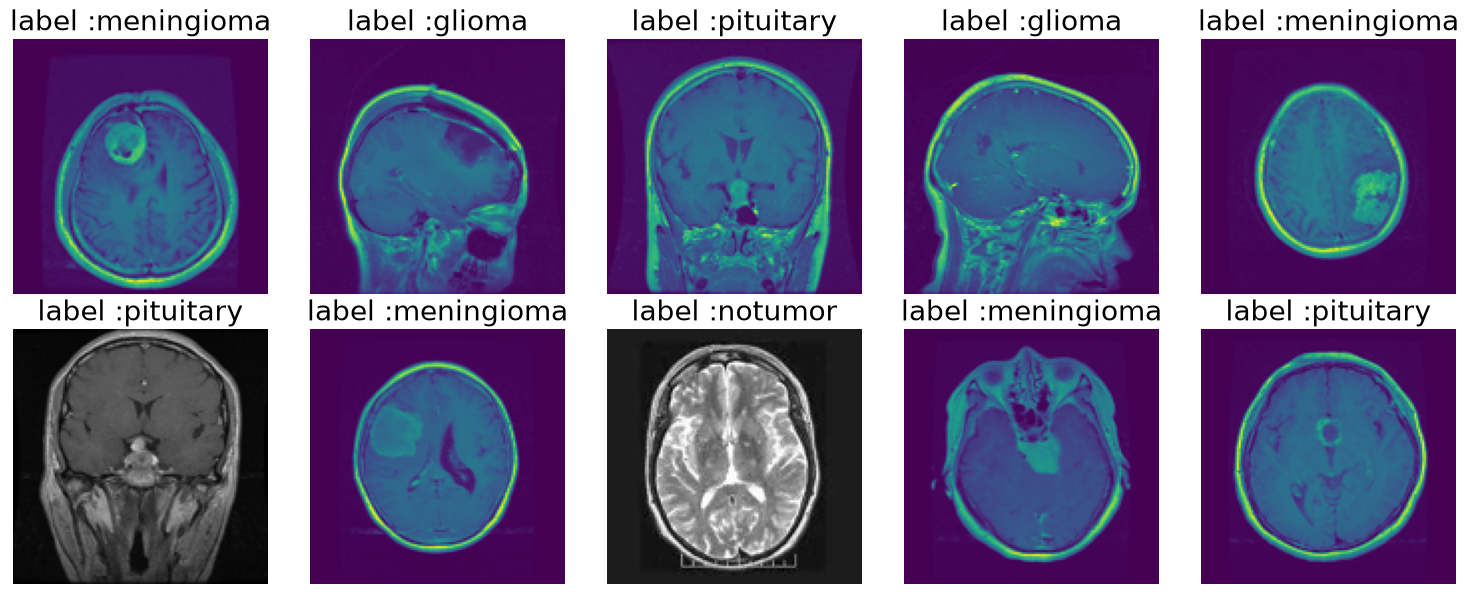

In [9]:
#data visualization
import random
import matplotlib.pyplot as plt

#select random indicies for 10 images
random_indices = random.sample(range(len(train_paths)), 10)
random_indices

#create a figure to display images in 2 rows
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

#loop through the random indices and display images
for i, idx in enumerate(random_indices):
  img_path = train_paths[idx]
  img = Image.open(img_path)
  img = img.resize((128, 128))

  #display images
  axes[i].imshow(img)
  axes[i].axis('off')
  axes[i].set_title(f"label :{train_labels[idx]}",fontsize=20)

plt.tight_layout()
plt.show()


# Image PreProcessing

In [12]:
#image augmentation function
def augment_image(image):
  image = Image.fromarray(np.uint8(image))
  image =ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
  image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
  image = np.array(image)/255.0
  return image

#load images and apply augementation
def open_images(paths):
  images = []
  for path in paths:
    image = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
    image = augment_image(image)
    images.append(image)
  return np.array(images)

#encoder labels(convert label names to integers)
def encode_label(labels):
  unique_labels = os.listdir(train_dir)
  encoded = [unique_labels.index(label) for label in labels]
  return np.array(encoded)

#data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
  for _ in range(epochs):
    for i in range(0, len(paths), batch_size):
      batch_paths = paths[i:i+batch_size]
      batch_images = open_images(batch_paths)
      batch_labels = labels[i:i+batch_size]
      batch_labels = encode_label(batch_labels)
      yield batch_images, batch_labels







In [13]:
os.listdir(train_dir)

['glioma', 'meningioma', 'notumor', 'pituitary']

# Trainning the Model

In [16]:
#model architecture
IMAGE_SIZE = 128
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')

#freeze all layers of this VGG16 base model
for layer in base_model.layers:
  layer.trainable = False

#set only the last few layers
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

#build model
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))
model.add(base_model)
model.add(GlobalAveragePooling2D())
model.add(Dropout(0.3))

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(len(os.listdir(train_dir)), activation='softmax'))

#compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

#parameters
batch_size = 20
steps = int(len(train_paths)/batch_size)
epochs = 5

#train model
history = model.fit(datagen(train_paths, train_labels, batch_size = batch_size, epochs =epochs), steps_per_epoch=steps, epochs=epochs)




C:\Users\user\Desktop\Colab Notebooks\MRI detection\MRI\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5
285/285 ━━━━━━━━━━━━━━━━━━━━ 1540s 5s/step - loss: 0.4945 - sparse_categorical_accuracy: 0.8065
Epoch 2/5
285/285 ━━━━━━━━━━━━━━━━━━━━ 1630s 6s/step - loss: 0.2560 - sparse_categorical_accuracy: 0.9041
Epoch 3/5
285/285 ━━━━━━━━━━━━━━━━━━━━ 1758s 6s/step - loss: 0.1817 - sparse_categorical_accuracy: 0.9362
Epoch 4/5
285/285 ━━━━━━━━━━━━━━━━━━━━ 1925s 7s/step - loss: 0.1198 - sparse_categorical_accuracy: 0.9554
Epoch 5/5
285/285 ━━━━━━━━━━━━━━━━━━━━ 1949s 7s/step - loss: 0.0883 - sparse_categorical_accuracy: 0.9668


## Trainning and val plots for accuracy and loss

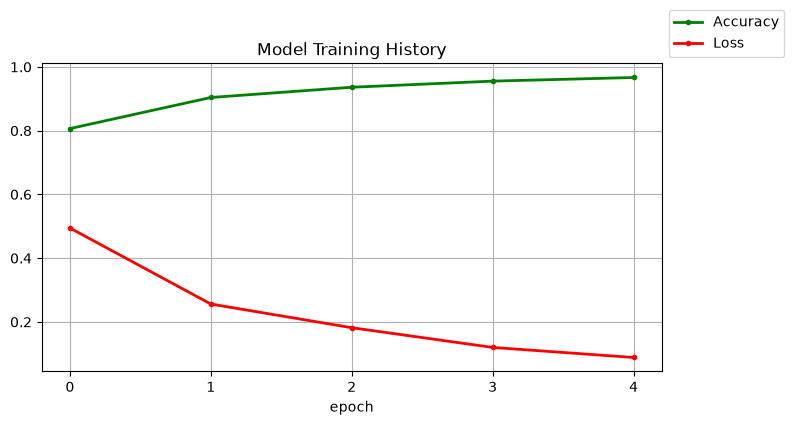

In [17]:
#train and val plots
import random #for generating random values for augmentation
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'],'.g-',linewidth=2)
plt.plot(history.history['loss'], '.r-', linewidth=2)
plt.title('Model Training History')
plt.xlabel('epoch')
plt.xticks([x for x in range(epochs)])
plt.legend(['Accuracy', 'Loss'], loc='lower left', bbox_to_anchor=(1,1))
plt.show()

# model Classification report 

In [18]:
#model classification report
from sklearn.metrics import classification_report,confusion_matrix, roc_curve,auc
import seaborn as sns
from sklearn.preprocessing import label_binarize
import numpy as np

test_images = open_images(test_paths)
test_labels_encoded = encode_label(test_labels)

test_predictions = model.predict(test_images)

print("classification Report:")
print(classification_report(test_labels_encoded, np.argmax(test_predictions, axis=1)))





41/41 ━━━━━━━━━━━━━━━━━━━━ 159s 4s/step
classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.93       300
           1       0.94      0.88      0.91       306
           2       0.95      1.00      0.97       405
           3       0.99      0.98      0.99       300

    accuracy                           0.95      1311
   macro avg       0.95      0.95      0.95      1311
weighted avg       0.95      0.95      0.95      1311



# model confusion plot

Confusion Matrix:
[[279  16   5   0]
 [ 20 270  13   3]
 [  2   0 403   0]
 [  2   2   1 295]]


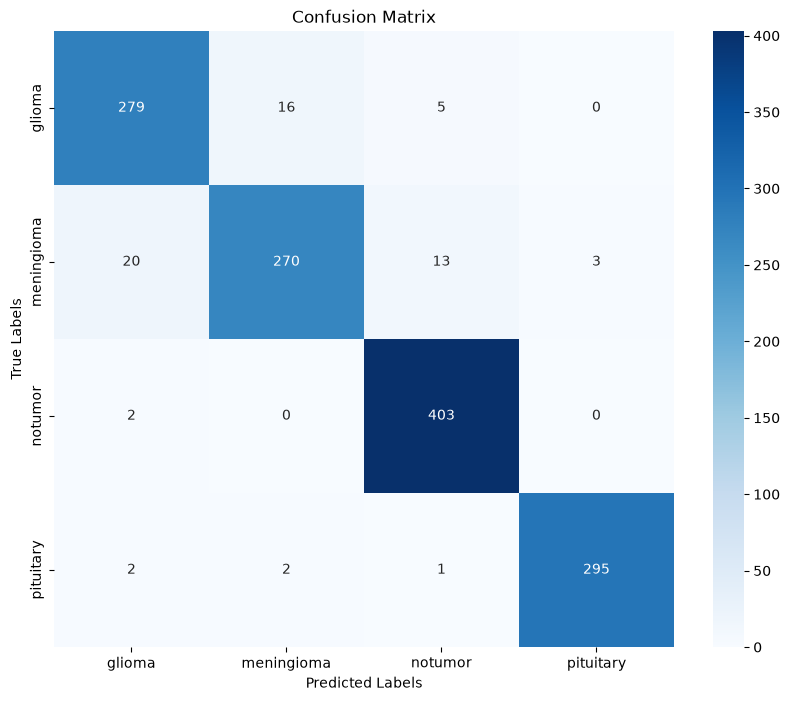

In [19]:
conf_matrix = confusion_matrix(test_labels_encoded, np.argmax(test_predictions, axis=1))
print("Confusion Matrix:")
print(conf_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=os.listdir(train_dir), yticklabels=os.listdir(train_dir))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# saving the model

In [21]:
model.save("brain_tumor_model.keras")

In [23]:
from tensorflow.keras.models import load_model

model = load_model("brain_tumor_model.keras", compile=False)

In [24]:
from keras.preprocessing.image import load_img, img_to_array

class_labels = ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
def detect_and_display(image_path,model):
  try:
    #load image
    image = load_img(image_path, target_size=(128, 128))
    image_array = img_to_array(image)
    image_array = np.expand_dims(image_array, axis=0)
    #prediction
    predictions = model.predict(image_array)
    predicted_class_index = np.argmax(predictions)
    confidence_score = np.max(predictions, axis=1)[0]

    #display the image
    plt.imshow(image)
    plt.axis('off')
    #determine the class
    if class_labels[predicted_class_index] == 'no_tumor':
      result = 'No Tumor Detected'
    else:
      result = f'Tumor Detected: {class_labels[predicted_class_index]}'
      #display
      plt.imshow(load_img(image_path))
      plt.axis('off')
      plt.show()
  except Exception as e:
    print('Error processing the image:', str(e))



In [ ]:
import shutil

shutil.make_archive(
    'MRI_Brain_Tumor_Project',
    'zip',
    '.'
)